# Deteksi URL Phishing dengan Seleksi Fitur dan Klasifikasi

Notebook ini membandingkan **Chi-Square, ANOVA F-test, dan Mutual Information** menggunakan **Random Forest** dan **Deep Neural Network (MLPClassifier)**.


## 1. Import Library

In [1]:
import random
import warnings
from pathlib import Path
from urllib.parse import urlparse

import numpy as np
import pandas as pd
import matplotlib as plt
import seaborn as sns
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.feature_selection import SelectKBest, chi2, f_classif, mutual_info_classif
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, matthews_corrcoef,
    confusion_matrix, balanced_accuracy_score
)
from sklearn.metrics import ConfusionMatrixDisplay
from ucimlrepo import fetch_ucirepo

warnings.filterwarnings("ignore")

## 2. Konfigurasi Eksperimen
Mengatur random seed dan folder keluaran.

In [2]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

OUTPUT_DIR = Path("hasil_phishing_sederhana")
OUTPUT_DIR.mkdir(exist_ok=True)

print("Random seed:", SEED)
print("Folder output:", OUTPUT_DIR.resolve())

Random seed: 42
Folder output: D:\Feature Selection Phishing\hasil_phishing_sederhana


## 3. Load Dataset

In [3]:
# Mengambil PhiUSIIL Phishing URL Dataset (ID: 967)
phiusiil = fetch_ucirepo(id=967)

# Menggabungkan fitur dan target
df = pd.concat(
    [phiusiil.data.features, phiusiil.data.targets],
    axis=1
)

# Informasi dataset
print("Ukuran data awal:", df.shape)
print("Jumlah baris:", f"{df.shape[0]:,}")
print("Jumlah kolom:", df.shape[1])
print("Jumlah missing value:", int(df.isna().sum().sum()))

print("Distribusi label:")
display(df["label"].value_counts().sort_index().to_frame("jumlah"))

# Validasi kolom
if "URL" not in df.columns or "label" not in df.columns:
    raise ValueError(
        "Dataset harus memiliki kolom URL dan label."
    )

Ukuran data awal: (235795, 55)
Jumlah baris: 235,795
Jumlah kolom: 55
Jumlah missing value: 0
Distribusi label:


,jumlah
label,
0,100945
1,134850


## 4. Exploratory Data Analysis (EDA)

Pemeriksaan awal struktur data, tipe data, missing values, duplikasi URL, ringkasan statistik, dan distribusi label dilakukan sebelum cleaning atau pemisahan data.

In [4]:
print("Informasi kolom dan tipe data:")
df.info()

print("\nMissing value per kolom:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing"))

print("\nJumlah URL duplikat:")
print(df["URL"].duplicated().sum() if "URL" in df.columns else "Kolom URL tidak ditemukan")

print("\nDistribusi label:")
display(df["label"].value_counts(dropna=False).sort_index().to_frame("jumlah"))
display((df["label"].value_counts(normalize=True, dropna=False).sort_index() * 100).round(2).to_frame("persentase"))

print("\nRingkasan statistik fitur numerik:")
display(df.select_dtypes(include="number").describe().T)

Informasi kolom dan tipe data:
<class 'pandas.DataFrame'>
RangeIndex: 235795 entries, 0 to 235794
Data columns (total 55 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   URL                         235795 non-null  str    
 1   URLLength                   235795 non-null  int64  
 2   Domain                      235795 non-null  str    
 3   DomainLength                235795 non-null  int64  
 4   IsDomainIP                  235795 non-null  int64  
 5   TLD                         235795 non-null  str    
 6   URLSimilarityIndex          235795 non-null  float64
 7   CharContinuationRate        235795 non-null  float64
 8   TLDLegitimateProb           235795 non-null  float64
 9   URLCharProb                 235795 non-null  float64
 10  TLDLength                   235795 non-null  int64  
 11  NoOfSubDomain               235795 non-null  int64  
 12  HasObfuscation              235795 non-null  int64  

,missing
URL,0
URLLength,0
Domain,0
DomainLength,0
IsDomainIP,0
TLD,0
URLSimilarityIndex,0
CharContinuationRate,0
TLDLegitimateProb,0
URLCharProb,0



Jumlah URL duplikat:
425

Distribusi label:


,jumlah
label,
0,100945
1,134850


,persentase
label,
0,42.81
1,57.19



Ringkasan statistik fitur numerik:


,count,mean,std,min,25%,50%,75%,max
URLLength,235795.0,34.573095,41.314153,13.000000,23.000000,27.000000,34.000000,6.097000e+03
DomainLength,235795.0,21.470396,9.150793,4.000000,16.000000,20.000000,24.000000,1.100000e+02
IsDomainIP,235795.0,0.002706,0.051946,0.000000,0.000000,0.000000,0.000000,1.000000e+00
URLSimilarityIndex,235795.0,78.430778,28.976055,0.155574,57.024793,100.000000,100.000000,1.000000e+02
CharContinuationRate,235795.0,0.845508,0.216632,0.000000,0.680000,1.000000,1.000000,1.000000e+00
TLDLegitimateProb,235795.0,0.260423,0.251628,0.000000,0.005977,0.079963,0.522907,5.229071e-01
URLCharProb,235795.0,0.055747,0.010587,0.001083,0.050747,0.057970,0.062875,9.082366e-02
TLDLength,235795.0,2.764456,0.599739,2.000000,2.000000,3.000000,3.000000,1.300000e+01
NoOfSubDomain,235795.0,1.164758,0.600969,0.000000,1.000000,1.000000,1.000000,1.000000e+01
HasObfuscation,235795.0,0.002057,0.045306,0.000000,0.000000,0.000000,0.000000,1.000000e+00


## 5. Data Cleaning dan Penyiapan Fitur

URL duplikat dihapus terlebih dahulu. Kolom identitas/teks yang tidak digunakan dikeluarkan dari prediktor, lalu domain URL disiapkan sebagai kelompok agar domain yang sama tidak masuk ke data training dan testing sekaligus.

**Catatan label:** `0 = phishing` dan `1 = legitimate`. Notebook mempertahankan label asli tersebut.

In [5]:
# Menghapus URL duplikat dan menyiapkan fitur
n_before = len(df)
df = df.drop_duplicates(subset="URL", keep="first").reset_index(drop=True)
print(f"URL duplikat yang dihapus: {n_before - len(df):,}")
print(f"Jumlah baris setelah deduplikasi: {len(df):,}")

def domain_key(url):
    url = str(url).strip().lower()
    if not url.startswith(("http://", "https://")):
        url = "http://" + url
    try:
        return urlparse(url).netloc.replace("www.", "")
    except Exception:
        return url

groups = df["URL"].map(domain_key)
drop_columns = [c for c in ["label", "URL", "Domain", "Title", "URLSimilarityIndex"] if c in df.columns]
X = df.drop(columns=drop_columns).select_dtypes(include="number")
y = df["label"].astype(int)

print("Kolom yang dikecualikan:", drop_columns)
print("Jumlah prediktor numerik:", X.shape[1])
print("Jumlah domain unik:", groups.nunique())
print("Label:", sorted(y.unique().tolist()))

if set(y.unique()) != {0, 1}:
    raise ValueError("Asumsi notebook: label 0 = phishing, label 1 = legitimate.")

URL duplikat yang dihapus: 425
Jumlah baris setelah deduplikasi: 235,370
Kolom yang dikecualikan: ['label', 'URL', 'Domain', 'Title', 'URLSimilarityIndex']
Jumlah prediktor numerik: 49
Jumlah domain unik: 219102
Label: [0, 1]


## 6. Train-Test Split

Data dibagi dengan pendekatan berbasis domain menggunakan `StratifiedGroupKFold`. Pemeriksaan overlap memastikan domain pada training dan test terpisah. Test set disimpan untuk evaluasi akhir dan tidak dipakai memilih konfigurasi.

In [6]:
# Membagi data training dan test berbasis domain
outer_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, test_idx = next(outer_cv.split(X, y, groups=groups))

X_train, X_test = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
y_train, y_test = y.iloc[train_idx].copy(), y.iloc[test_idx].copy()
groups_train, groups_test = groups.iloc[train_idx], groups.iloc[test_idx]

assert set(groups_train).isdisjoint(set(groups_test)), "Ada domain yang muncul di train dan test."

print("Train:", X_train.shape, "| Test:", X_test.shape)
print(f"Proporsi test: {len(X_test) / len(X):.3f}")
print("Domain train/test:", groups_train.nunique(), "/", groups_test.nunique())
print("Overlap domain:", len(set(groups_train) & set(groups_test)))
print("Distribusi label train:", y_train.value_counts(normalize=True).round(4).to_dict())
print("Distribusi label test :", y_test.value_counts(normalize=True).round(4).to_dict())

Train: (188297, 49) | Test: (47073, 49)
Proporsi test: 0.200
Domain train/test: 175288 / 43814
Overlap domain: 0
Distribusi label train: {1: 0.5729, 0: 0.4271}
Distribusi label test : {1: 0.5729, 0: 0.4271}


## 7. Preprocessing, Feature Selection, dan Metrik


In [7]:
# Mendefinisikan pipeline model dan fungsi evaluasi
FEATURE_SELECTORS = {
    "Chi-Square": chi2,
    "ANOVA F-test": f_classif,
    "Mutual Information": lambda X_, y_: mutual_info_classif(X_, y_, random_state=SEED),
}
SUBSETS = [10, 20, 30, 40, "All Features"]
MODELS = ["Random Forest", "Deep Neural Network"]

def make_pipeline(model_name, selector_name=None, subset="All Features"):
    if model_name == "Random Forest":
        classifier = RandomForestClassifier(
            n_estimators=300, random_state=SEED, n_jobs=-1,
            class_weight="balanced", max_features="sqrt"
        )
    else:
        classifier = MLPClassifier(
            hidden_layer_sizes=(128, 64, 32), activation="relu",
            solver="adam", alpha=1e-4, batch_size=256,
            learning_rate_init=1e-3, max_iter=100,
            early_stopping=True, validation_fraction=0.15,
            n_iter_no_change=10, random_state=SEED
        )

    steps = [("imputer", SimpleImputer(strategy="median"))]
    if selector_name == "Chi-Square":
        steps.append(("scaler", MinMaxScaler()))
    elif model_name == "Deep Neural Network":
        steps.append(("scaler", StandardScaler()))

    if selector_name is not None:
        k = "all" if subset == "All Features" else min(int(subset), X_train.shape[1])
        steps.append(("selector", SelectKBest(FEATURE_SELECTORS[selector_name], k=k)))

    steps.append(("classifier", classifier))
    return Pipeline(steps)

def phishing_probability(pipe, X_part):
    class_index = list(pipe.named_steps["classifier"].classes_).index(0)
    return pipe.predict_proba(X_part)[:, class_index]

def calculate_metrics(y_true, y_pred, phishing_prob):
    # Jadikan phishing (label 0) sebagai kelas positif untuk precision/recall/F1.
    true_phishing = (np.asarray(y_true) == 0).astype(int)
    pred_phishing = (np.asarray(y_pred) == 0).astype(int)
    tn, fp, fn, tp = confusion_matrix(true_phishing, pred_phishing, labels=[0, 1]).ravel()

    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(true_phishing, pred_phishing, zero_division=0),
        "recall": recall_score(true_phishing, pred_phishing, zero_division=0),
        "specificity": tn / (tn + fp) if (tn + fp) else np.nan,
        "f1": f1_score(true_phishing, pred_phishing, zero_division=0),
        "roc_auc": roc_auc_score(true_phishing, phishing_prob),
        "pr_auc": average_precision_score(true_phishing, phishing_prob),
        "mcc": matthews_corrcoef(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
    }

## 8. Eksperimen Cross-Validation

Dua model dibandingkan: Random Forest dan Deep Neural Network (`MLPClassifier`). 

Untuk setiap model diuji tiga metode seleksi fitur : Chi-Square, ANOVA F-test, dan Mutual Information. Subset Top-10, Top-20, Top-30, Top-40, dan seluruh fitur. Baseline tanpa seleksi fitur juga dihitung.

In [8]:
# Menjalankan cross-validation untuk konfigurasi seleksi fitur dan baseline
# Imputasi, scaling, dan seleksi fitur di-fit di dalam setiap training fold.

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_rows = []
configurations = [
    (model, selector, subset)
    for model in MODELS
    for selector in FEATURE_SELECTORS
    for subset in SUBSETS
]
configurations += [(model, "No Feature Selection", "All Features") for model in MODELS]

for model_name, selector_name, subset in configurations:
    print(f"CV: {model_name} | {selector_name} | {subset}")
    for fold, (tr_idx, val_idx) in enumerate(
        cv.split(X_train, y_train, groups=groups_train), start=1
    ):
        X_tr, X_val = X_train.iloc[tr_idx], X_train.iloc[val_idx]
        y_tr, y_val = y_train.iloc[tr_idx], y_train.iloc[val_idx]

        if selector_name == "No Feature Selection":
            pipe = make_pipeline(model_name)
        else:
            pipe = make_pipeline(model_name, selector_name, subset)

        pipe.fit(X_tr, y_tr)
        pred = pipe.predict(X_val)
        prob = phishing_probability(pipe, X_val)
        cv_rows.append({
            "model": model_name,
            "feature_selection": selector_name,
            "subset": str(subset),
            "fold": fold,
            **calculate_metrics(y_val, pred, prob)
        })

cv_results = pd.DataFrame(cv_rows)
cv_results.to_csv(OUTPUT_DIR / "cv_fold_results.csv", index=False)
print("Jumlah baris hasil CV:", len(cv_results))
display(cv_results.head())

CV: Random Forest | Chi-Square | 10
CV: Random Forest | Chi-Square | 20
CV: Random Forest | Chi-Square | 30
CV: Random Forest | Chi-Square | 40
CV: Random Forest | Chi-Square | All Features
CV: Random Forest | ANOVA F-test | 10
CV: Random Forest | ANOVA F-test | 20
CV: Random Forest | ANOVA F-test | 30
CV: Random Forest | ANOVA F-test | 40
CV: Random Forest | ANOVA F-test | All Features
CV: Random Forest | Mutual Information | 10
CV: Random Forest | Mutual Information | 20
CV: Random Forest | Mutual Information | 30
CV: Random Forest | Mutual Information | 40
CV: Random Forest | Mutual Information | All Features
CV: Deep Neural Network | Chi-Square | 10
CV: Deep Neural Network | Chi-Square | 20
CV: Deep Neural Network | Chi-Square | 30
CV: Deep Neural Network | Chi-Square | 40
CV: Deep Neural Network | Chi-Square | All Features
CV: Deep Neural Network | ANOVA F-test | 10
CV: Deep Neural Network | ANOVA F-test | 20
CV: Deep Neural Network | ANOVA F-test | 30
CV: Deep Neural Network | AN

,model,feature_selection,subset,fold,accuracy,precision,recall,specificity,f1,roc_auc,pr_auc,mcc,balanced_accuracy,TN,FP,FN,TP
0,Random Forest,Chi-Square,10,1,0.973526,0.964013,0.974383,0.972887,0.969170,0.996118,0.995274,0.946016,0.973635,20991,585,412,15671
1,Random Forest,Chi-Square,10,2,0.973552,0.964187,0.974259,0.973026,0.969197,0.996356,0.995091,0.946065,0.973642,20994,582,414,15669
2,Random Forest,Chi-Square,10,3,0.972623,0.962001,0.974383,0.971311,0.968152,0.996035,0.994579,0.944206,0.972847,20957,619,412,15671
3,Random Forest,Chi-Square,10,4,0.974668,0.960885,0.980601,0.970246,0.970643,0.996885,0.995986,0.948521,0.975423,20935,642,312,15771
4,Random Forest,Chi-Square,10,5,0.967552,0.960809,0.963318,0.970708,0.962061,0.995876,0.994437,0.933718,0.967013,20944,632,590,15494


## 9. Ringkasan CV dan Pemilihan Konfigurasi

 Konfigurasi terbaik untuk setiap model dipilih berdasarkan **mean MCC pada data training**, bukan berdasarkan hasil test.

In [9]:
# Merangkum hasil CV dan memilih konfigurasi berdasarkan mean MCC
metric_columns = [
    "accuracy", "precision", "recall", "specificity", "f1",
    "roc_auc", "pr_auc", "mcc", "balanced_accuracy"
]
agg_dict = {}
for metric in metric_columns:
    agg_dict[f"{metric}_mean"] = (metric, "mean")
    agg_dict[f"{metric}_std"] = (metric, "std")

cv_summary = (
    cv_results.groupby(["model", "feature_selection", "subset"])
    .agg(**agg_dict).reset_index()
    .sort_values(["model", "mcc_mean"], ascending=[True, False])
)
cv_summary.to_csv(OUTPUT_DIR / "cv_summary.csv", index=False)

# Pilih hanya dari 30 konfigurasi seleksi fitur, bukan dari hasil test.
candidates = cv_summary[cv_summary["feature_selection"] != "No Feature Selection"].copy()
selected_configs = (
    candidates.sort_values("mcc_mean", ascending=False)
    .groupby("model", as_index=False).head(1).reset_index(drop=True)
)

print("Konfigurasi terpilih berdasarkan mean CV MCC:")
display(selected_configs[["model", "feature_selection", "subset", "mcc_mean", "mcc_std"]])

Konfigurasi terpilih berdasarkan mean CV MCC:


,model,feature_selection,subset,mcc_mean,mcc_std
0,Random Forest,Chi-Square,All Features,0.999718,0.000124
1,Deep Neural Network,Mutual Information,20,0.999392,0.000197


## 10. Perbandingan dengan Baseline



In [10]:
# Membandingkan konfigurasi terpilih dengan baseline menggunakan hasil CV
baseline = cv_summary[cv_summary["feature_selection"] == "No Feature Selection"][
    ["model", "mcc_mean", "accuracy_mean", "f1_mean"]
].copy()
best = selected_configs[
    ["model", "feature_selection", "subset", "mcc_mean", "accuracy_mean", "f1_mean"]
].copy()

cv_comparison = best.merge(baseline, on="model", suffixes=("_selected", "_baseline"))
cv_comparison["delta_mcc"] = cv_comparison["mcc_mean_selected"] - cv_comparison["mcc_mean_baseline"]
display(cv_comparison)
cv_comparison.to_csv(OUTPUT_DIR / "cv_selected_vs_baseline.csv", index=False)

,model,feature_selection,subset,mcc_mean_selected,accuracy_mean_selected,f1_mean_selected,mcc_mean_baseline,accuracy_mean_baseline,f1_mean_baseline,delta_mcc
0,Random Forest,Chi-Square,All Features,0.999718,0.999862,0.999838,0.999685,0.999846,0.999820,0.000033
1,Deep Neural Network,Mutual Information,20,0.999392,0.999703,0.999652,0.999099,0.999559,0.999484,0.000293


## 11. Evaluasi Akhir pada Test Set

Evaluasi dilakukan satu kali pada test set yang tidak digunakan saat pemilihan konfigurasi.

In [11]:
# Melatih konfigurasi terpilih dan mengevaluasi test set
# Test tidak digunakan untuk memilih konfigurasi.

final_models = {}
final_rows = []

for _, row in selected_configs.iterrows():
    model_name = row["model"]
    pipe = make_pipeline(model_name, row["feature_selection"], row["subset"])
    pipe.fit(X_train, y_train)
    final_models[model_name] = pipe

    pred = pipe.predict(X_test)
    prob = phishing_probability(pipe, X_test)
    final_rows.append({
        "model": model_name,
        "feature_selection": row["feature_selection"],
        "subset": row["subset"],
        "cv_mcc_mean": row["mcc_mean"],
        **calculate_metrics(y_test, pred, prob)
    })

final_test_results = pd.DataFrame(final_rows)
display(final_test_results)
final_test_results.to_csv(OUTPUT_DIR / "final_test_results.csv", index=False)

,model,feature_selection,subset,cv_mcc_mean,accuracy,precision,recall,specificity,f1,roc_auc,pr_auc,mcc,balanced_accuracy,TN,FP,FN,TP
0,Random Forest,Chi-Square,All Features,0.999718,0.999873,0.999950,0.999751,0.999963,0.999851,1.000000,0.999999,0.999740,0.999857,26968,1,5,20099
1,Deep Neural Network,Mutual Information,20,0.999392,0.999681,0.999751,0.999503,0.999815,0.999627,0.999999,0.999998,0.999349,0.999659,26964,5,10,20094


## 12. Visualisasi Hasil Eksperimen



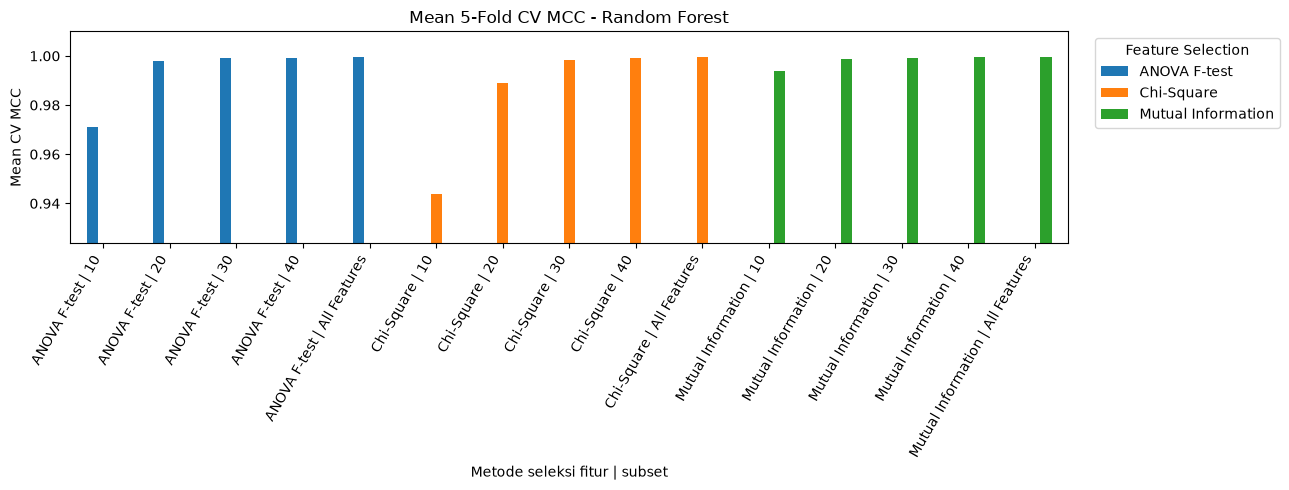

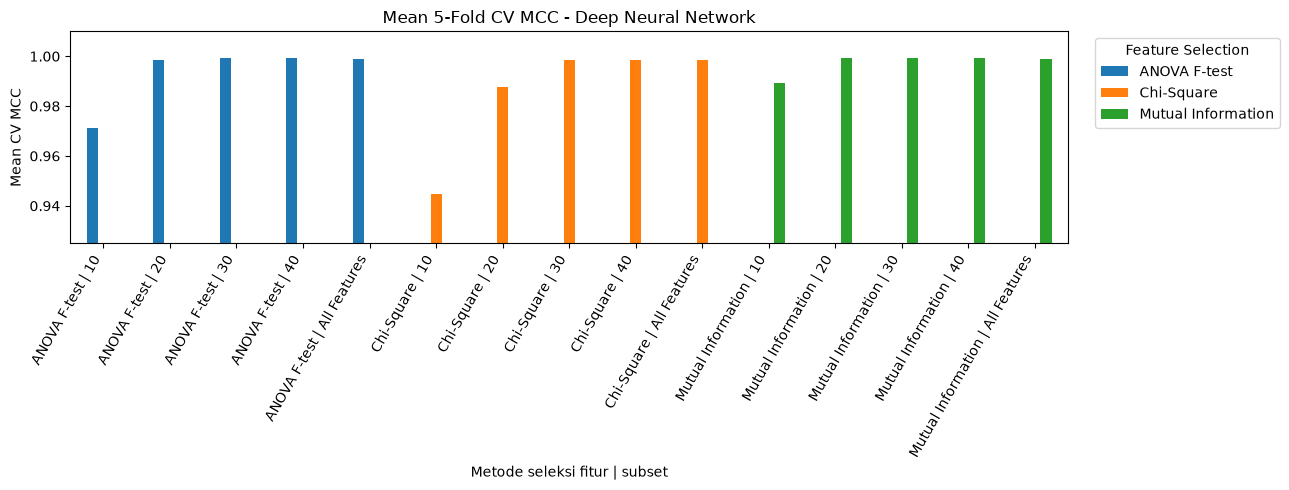

In [12]:

# Memvisualisasikan mean CV MCC per model, metode, dan subset fitur

import matplotlib.pyplot as plt

plot_data = cv_summary[
    cv_summary["feature_selection"] != "No Feature Selection"
].copy()

plot_data["configuration"] = (
    plot_data["feature_selection"]
    + " | "
    + plot_data["subset"].astype(str)
)

for model_name in MODELS:
    part = plot_data[
        plot_data["model"] == model_name
    ].copy()

    pivot = part.pivot(
        index="configuration",
        columns="feature_selection",
        values="mcc_mean"
    )

    ax = pivot.plot(
        kind="bar",
        figsize=(13, 5)
    )

    ax.set_title(f"Mean 5-Fold CV MCC - {model_name}")
    ax.set_xlabel("Metode seleksi fitur | subset")
    ax.set_ylabel("Mean CV MCC")

    # Menentukan batas sumbu Y
    y_min = max(0, float(pivot.min().min()) - 0.02)
    ax.set_ylim(y_min, 1.01)

    # Memiringkan label sumbu X tanpa plt.xticks()
    ax.tick_params(axis="x", labelrotation=60)

    for label in ax.get_xticklabels():
        label.set_horizontalalignment("right")

    ax.legend(
        title="Feature Selection",
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )

    plt.tight_layout()
    plt.show()


### 12.1 Performa pada Test Set


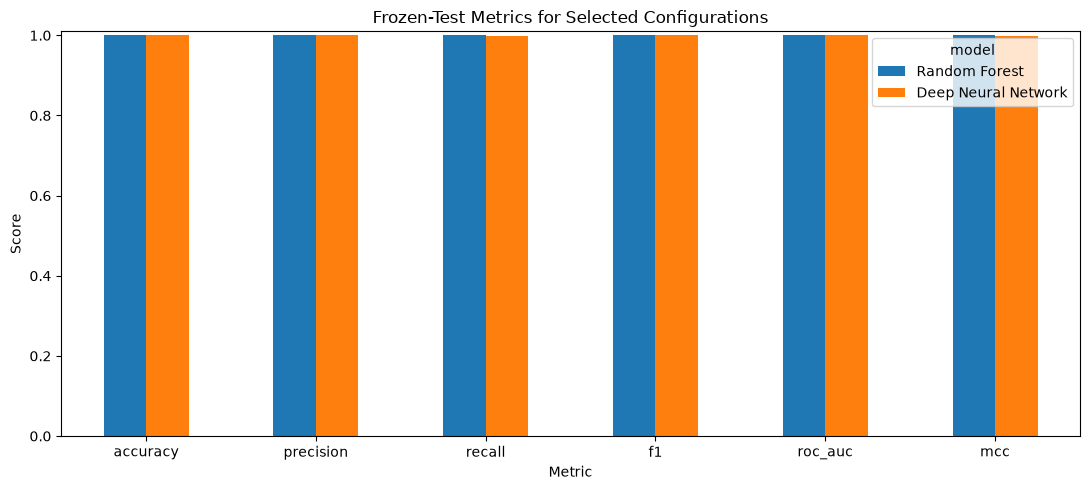

Random Forest | Chi-Square | All Features


,Predicted Legitimate,Predicted Phishing
Actual Legitimate,26968,1
Actual Phishing,5,20099


Deep Neural Network | Mutual Information | 20


,Predicted Legitimate,Predicted Phishing
Actual Legitimate,26964,5
Actual Phishing,10,20094


Hasil tersimpan di: D:\Feature Selection Phishing\hasil_phishing_sederhana


In [13]:
# Memvisualisasikan metrik test dan confusion matrix
plot_metrics = ["accuracy", "precision", "recall", "f1", "roc_auc", "mcc"]
ax = final_test_results.set_index("model")[plot_metrics].T.plot(kind="bar", figsize=(11, 5))
ax.set_title("Frozen-Test Metrics for Selected Configurations")
ax.set_xlabel("Metric")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.01)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

for _, row in final_test_results.iterrows():
    cm = pd.DataFrame(
        [[row["TN"], row["FP"]], [row["FN"], row["TP"]]],
        index=["Actual Legitimate", "Actual Phishing"],
        columns=["Predicted Legitimate", "Predicted Phishing"]
    )
    print(f"{row['model']} | {row['feature_selection']} | {row['subset']}")
    display(cm)

print("Hasil tersimpan di:", OUTPUT_DIR.resolve())

## 13. Tabel Lengkap Hasil Cross-Validation


In [14]:

# Menampilkan dan menyimpan seluruh skor cross-validation

pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)

cv_scores_all = cv_summary.sort_values(
    ["model", "feature_selection", "subset"]
).reset_index(drop=True)

display(cv_scores_all)

# Simpan hasil lengkap
cv_scores_all.to_csv(
    OUTPUT_DIR / "cross_validation_scores_all_configurations.csv",
    index=False
)


,model,feature_selection,subset,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,specificity_mean,specificity_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std,mcc_mean,mcc_std,balanced_accuracy_mean,balanced_accuracy_std
0,Deep Neural Network,ANOVA F-test,10,0.985879,0.003026,0.984399,0.002768,0.982504,0.004671,0.988395,0.002051,0.983448,0.003561,0.999000,3.180740e-04,0.998701,4.260621e-04,0.971139,0.006189,0.985449,0.003223
1,Deep Neural Network,ANOVA F-test,20,0.999246,0.000221,0.999378,0.000365,0.998856,0.000251,0.999537,0.000272,0.999117,0.000259,0.999977,2.237417e-05,0.999977,1.839734e-05,0.998459,0.000452,0.999196,0.000218
2,Deep Neural Network,ANOVA F-test,30,0.999692,0.000102,0.999801,0.000081,0.999478,0.000243,0.999852,0.000060,0.999639,0.000120,0.999976,3.354350e-05,0.999980,2.467616e-05,0.999371,0.000209,0.999665,0.000119
3,Deep Neural Network,ANOVA F-test,40,0.999602,0.000084,0.999689,0.000187,0.999378,0.000076,0.999768,0.000139,0.999534,0.000098,0.999974,3.464551e-05,0.999977,2.835804e-05,0.999186,0.000172,0.999573,0.000077
4,Deep Neural Network,ANOVA F-test,All Features,0.999559,0.000159,0.999490,0.000522,0.999478,0.000313,0.999620,0.000390,0.999484,0.000186,0.999992,1.057998e-05,0.999990,1.180030e-05,0.999099,0.000324,0.999549,0.000138
5,Deep Neural Network,Chi-Square,10,0.973048,0.002705,0.970917,0.003516,0.965828,0.004287,0.978430,0.002654,0.968361,0.003190,0.996739,3.286573e-04,0.995550,4.864544e-04,0.944903,0.005536,0.972129,0.002836
6,Deep Neural Network,Chi-Square,20,0.993994,0.000287,0.994265,0.000686,0.991656,0.000808,0.995736,0.000515,0.992959,0.000338,0.999669,6.857680e-05,0.999614,6.432589e-05,0.987725,0.000587,0.993696,0.000321
7,Deep Neural Network,Chi-Square,30,0.999187,0.000141,0.999403,0.000287,0.998694,0.000159,0.999555,0.000214,0.999048,0.000165,0.999978,1.990501e-05,0.999977,1.558895e-05,0.998340,0.000289,0.999125,0.000134
8,Deep Neural Network,Chi-Square,40,0.999262,0.000308,0.999266,0.000261,0.999005,0.000721,0.999453,0.000195,0.999136,0.000361,0.999980,1.917739e-05,0.999979,1.602160e-05,0.998492,0.000628,0.999229,0.000356
9,Deep Neural Network,Chi-Square,All Features,0.999262,0.000127,0.999316,0.000512,0.998955,0.000246,0.999490,0.000382,0.999136,0.000148,0.999979,1.429076e-05,0.999977,1.339606e-05,0.998492,0.000258,0.999223,0.000088


## 14. Confusion Matrix Konfigurasi Terpilih


In [15]:

# Menampilkan confusion matrix untuk seluruh model terpilih

for model_name, pipe in final_models.items():
    y_pred = pipe.predict(X_test)

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[1, 0]
    )

    cm_df = pd.DataFrame(
        cm,
        index=["Actual Legitimate", "Actual Phishing"],
        columns=["Predicted Legitimate", "Predicted Phishing"]
    )

    print(f"\nConfusion Matrix - {model_name}")
    display(cm_df)



Confusion Matrix - Random Forest


,Predicted Legitimate,Predicted Phishing
Actual Legitimate,26968,1
Actual Phishing,5,20099



Confusion Matrix - Deep Neural Network


,Predicted Legitimate,Predicted Phishing
Actual Legitimate,26964,5
Actual Phishing,10,20094


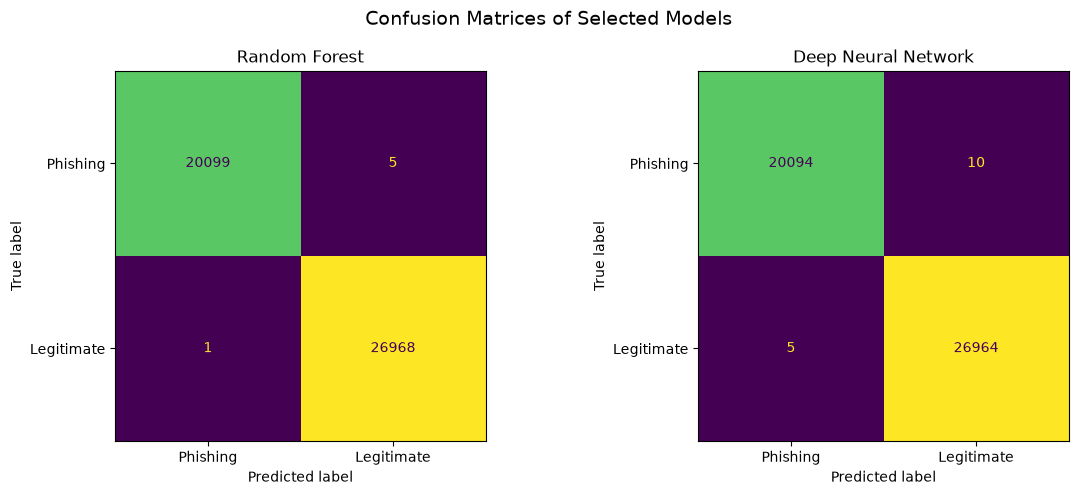

In [19]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
import matplotlib.pyplot as plt

# Hitung confusion matrix
cm_rf = confusion_matrix(
    y_test,
    final_models["Random Forest"].predict(X_test),
    labels=[0, 1]
)

cm_dnn = confusion_matrix(
    y_test,
    final_models["Deep Neural Network"].predict(X_test),
    labels=[0, 1]
)

# Plot berdampingan
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

display_labels = ["Phishing", "Legitimate"]

ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=display_labels
).plot(ax=axes[0], values_format="d", colorbar=False)

axes[0].set_title("Random Forest")

ConfusionMatrixDisplay(
    confusion_matrix=cm_dnn,
    display_labels=display_labels
).plot(ax=axes[1], values_format="d", colorbar=False)

axes[1].set_title("Deep Neural Network")

fig.suptitle("Confusion Matrices of Selected Models", fontsize=14)
plt.tight_layout()
plt.show()

## 15. Analisis Ranking Fitur

Skor fitur dihitung menggunakan data training.

In [20]:

# Menghitung ranking Top-10 fitur menggunakan data training

# Imputasi berdasarkan training partition
imputer = SimpleImputer(strategy="median")
X_train_rank = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

# Chi-Square membutuhkan fitur non-negatif
scaler = MinMaxScaler()
X_train_chi2 = scaler.fit_transform(X_train_rank)

# Hitung feature importance scores
chi2_scores, _ = chi2(X_train_chi2, y_train)
anova_scores, _ = f_classif(X_train_rank, y_train)
mi_scores = mutual_info_classif(
    X_train_rank,
    y_train,
    random_state=SEED
)

# Tabel ranking Chi-Square
chi2_ranking = pd.DataFrame({
    "Feature": X_train.columns,
    "Score": chi2_scores
}).sort_values("Score", ascending=False).head(10).reset_index(drop=True)

chi2_ranking.index = chi2_ranking.index + 1
chi2_ranking.index.name = "Rank"

print("Top-10 Features - Chi-Square")
display(chi2_ranking)

# Tabel ranking ANOVA F-test
anova_ranking = pd.DataFrame({
    "Feature": X_train.columns,
    "Score": anova_scores
}).sort_values("Score", ascending=False).head(10).reset_index(drop=True)

anova_ranking.index = anova_ranking.index + 1
anova_ranking.index.name = "Rank"

print("Top-10 Features - ANOVA F-test")
display(anova_ranking)

# Tabel ranking Mutual Information
mi_ranking = pd.DataFrame({
    "Feature": X_train.columns,
    "Score": mi_scores
}).sort_values("Score", ascending=False).head(10).reset_index(drop=True)

mi_ranking.index = mi_ranking.index + 1
mi_ranking.index.name = "Rank"

print("Top-10 Features - Mutual Information")
display(mi_ranking)



Top-10 Features - Chi-Square


,Feature,Score
Rank,,
1,HasSocialNet,62790.693276
2,HasCopyrightInfo,53218.631053
3,HasDescription,49844.822668
4,HasSubmitButton,37012.305234
5,DomainTitleMatchScore,31717.149442
6,HasHiddenFields,30251.734058
7,HasFavicon,28836.804996
8,URLTitleMatchScore,26376.107494
9,Robots,21210.693911


Top-10 Features - ANOVA F-test


,Feature,Score
Rank,,
1,HasSocialNet,300413.696676
2,HasCopyrightInfo,231885.883754
3,HasDescription,169208.734529
4,IsHTTPS,112226.360670
5,DomainTitleMatchScore,98077.743683
6,HasSubmitButton,94989.178100
7,IsResponsive,80268.994723
8,URLTitleMatchScore,79132.804781
9,SpacialCharRatioInURL,76309.918441


Top-10 Features - Mutual Information


,Feature,Score
Rank,,
1,LineOfCode,0.602324
2,NoOfExternalRef,0.561285
3,NoOfImage,0.543295
4,NoOfSelfRef,0.526448
5,NoOfJS,0.500806
6,LargestLineLength,0.486942
7,NoOfCSS,0.445531
8,HasSocialNet,0.409978
9,LetterRatioInURL,0.380963


### 15.1 Visualisasi Top-10 Fitur


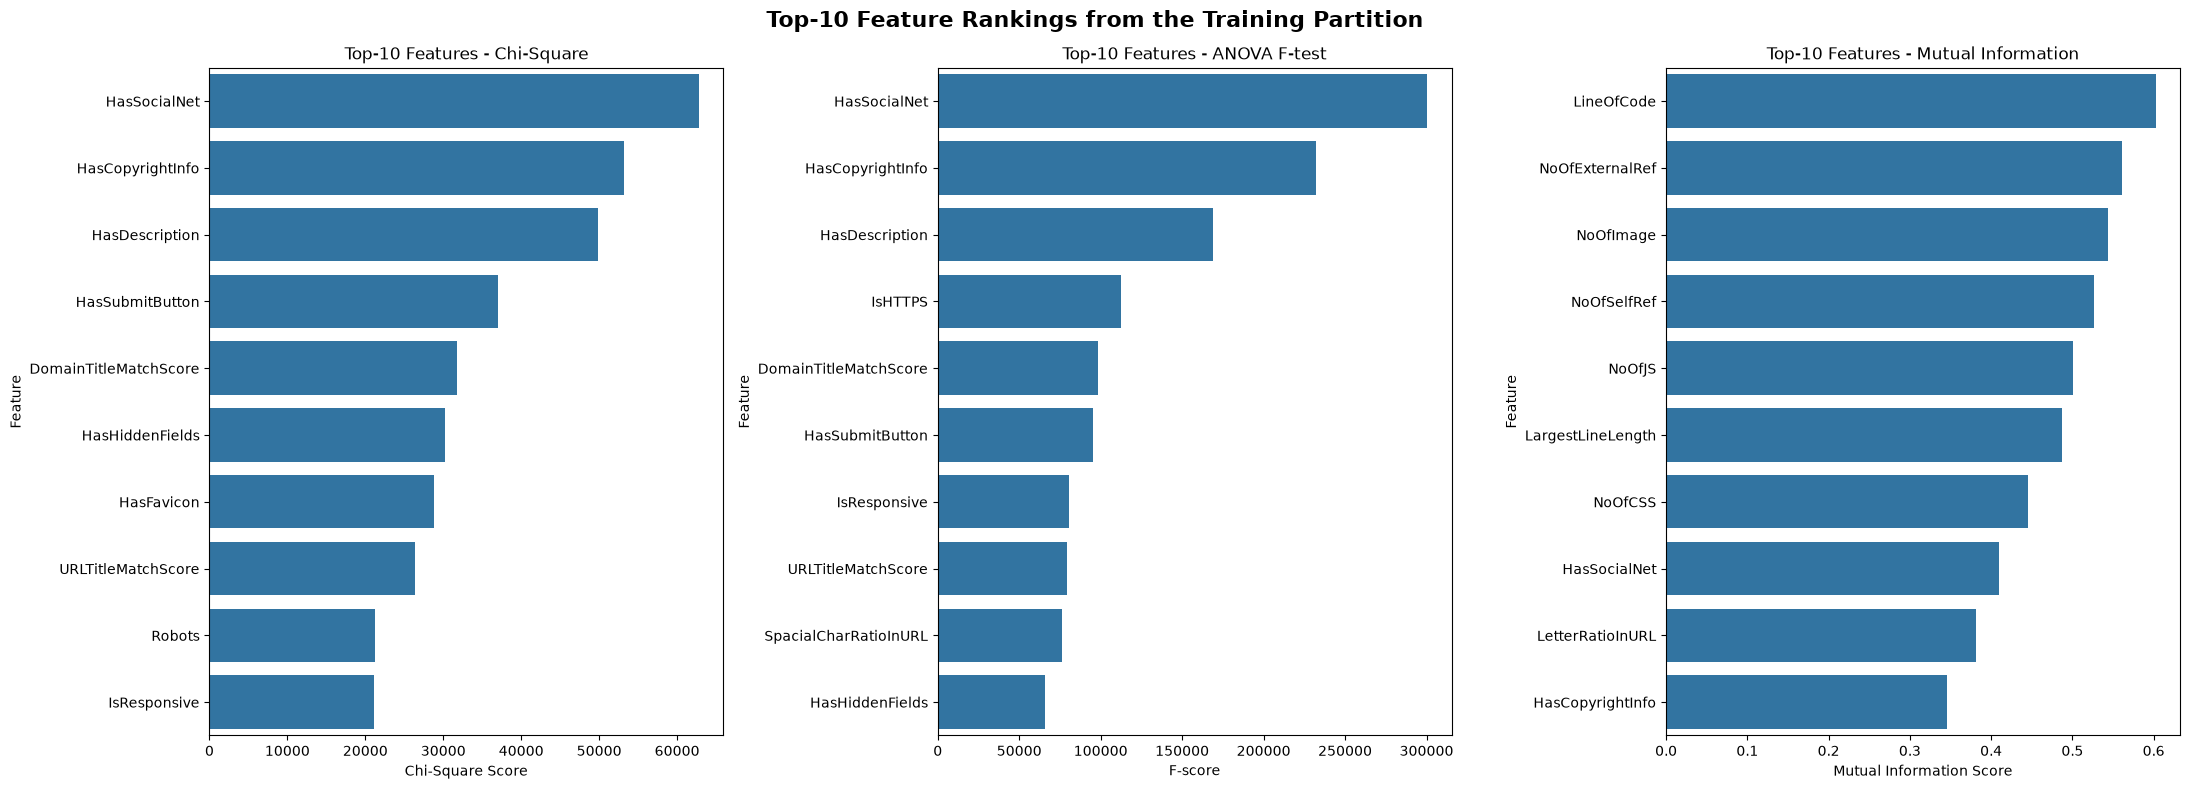

In [21]:
# Memvisualisasikan ranking Top-10 fitur
fig, axes = plt.subplots(1, 3, figsize=(22, 8))

sns.barplot(
    data=chi2_ranking,
    x="Score",
    y="Feature",
    ax=axes[0]
)
axes[0].set_title("Top-10 Features - Chi-Square")
axes[0].set_xlabel("Chi-Square Score")
axes[0].set_ylabel("Feature")

sns.barplot(
    data=anova_ranking,
    x="Score",
    y="Feature",
    ax=axes[1]
)
axes[1].set_title("Top-10 Features - ANOVA F-test")
axes[1].set_xlabel("F-score")
axes[1].set_ylabel("Feature")

sns.barplot(
    data=mi_ranking,
    x="Score",
    y="Feature",
    ax=axes[2]
)
axes[2].set_title("Top-10 Features - Mutual Information")
axes[2].set_xlabel("Mutual Information Score")
axes[2].set_ylabel("Feature")

plt.suptitle(
    "Top-10 Feature Rankings from the Training Partition",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


## 16. Pemeriksaan Konfigurasi Terpilih


In [22]:
print("Jumlah konfigurasi:", len(selected_configs))
print(selected_configs[["model", "feature_selection", "subset"]])

Jumlah konfigurasi: 2
                 model   feature_selection        subset
0        Random Forest          Chi-Square  All Features
1  Deep Neural Network  Mutual Information            20


# Analisis 

### 1. Performa Model

| **Tahap** | **Random Forest** | **Deep Neural Network** |
|---|---:|---:|
| Baseline (5-fold CV) | MCC: 0.999685 | MCC: 0.999099 |
| Konfigurasi terbaik (5-fold CV) | MCC: 0.999718 ± 0.000124 | MCC: 0.999392 ± 0.000197 |
| Evaluasi test set | Accuracy: 99.9873% | Accuracy: 99.9681% |
| MCC test set | 0.999740 | 0.999349 |

Random Forest dengan metode Chi-Square menggunakan seluruh 49 fitur menjadi model terbaik berdasarkan hasil eksperimen. Sementara itu, DNN memperoleh hasil terbaik menggunakan Mutual Information dengan 20 fitur. Kedua model menunjukkan performa sangat tinggi, tetapi Random Forest memberikan hasil yang lebih baik pada evaluasi cross-validation maupun test set.

### 2. Dataset

Dataset PhiUSIIL yang digunakan memiliki dua kelas, yaitu phishing dan legitimate. Pembagian data dilakukan berdasarkan domain untuk mengurangi risiko domain yang sama muncul pada data training dan test set. Meskipun demikian, pemisahan tersebut belum menjamin model dapat mengenali URL dari sumber dan periode yang berbeda.

### 3. Pengaruh Seleksi Fitur

Hasil eksperimen menunjukkan bahwa seleksi fitur meningkatkan MCC dibandingkan baseline tanpa seleksi. Pada Random Forest, MCC meningkat dari 0.999685 menjadi 0.999718. Pada DNN, MCC meningkat dari 0.999099 menjadi 0.999392.

Hasil ini menunjukkan bahwa seleksi fitur dapat membantu meningkatkan performa model, meskipun peningkatannya relatif kecil pada Random Forest. Metode terbaik juga berbeda pada setiap algoritma, sehingga pemilihan fitur perlu disesuaikan dengan model yang digunakan.

### 4. Confusion Matrix dan Ranking Fitur

Random Forest menghasilkan 6 kesalahan klasifikasi, sedangkan DNN menghasilkan 15 kesalahan. Pada kasus URL phishing yang diprediksi sebagai legitimate, Random Forest melakukan 5 kesalahan dan DNN melakukan 10 kesalahan. Hal ini menunjukkan bahwa Random Forest lebih baik dalam mengurangi kesalahan deteksi phishing pada test set.

Berdasarkan ranking fitur, Chi-Square dan ANOVA F-test menempatkan `HasSocialNet`, `HasCopyrightInfo`, dan `HasDescription` sebagai tiga fitur teratas. Sementara itu, Mutual Information menempatkan `LineOfCode`, `NoOfExternalRef`, dan `NoOfImage` pada posisi teratas. Perbedaan ini menunjukkan bahwa setiap metode seleksi fitur memiliki cara berbeda dalam menilai relevansi fitur terhadap target klasifikasi.

### 5. Hipotesis

1. Random Forest menunjukkan performa lebih baik dibandingkan DNN berdasarkan hasil cross-validation dan evaluasi test set.
2. Seleksi fitur meningkatkan MCC kedua model dibandingkan baseline tanpa seleksi fitur.
3. Chi-Square dengan seluruh 49 fitur menjadi konfigurasi terbaik untuk Random Forest, sedangkan Mutual Information dengan 20 fitur menjadi konfigurasi terbaik untuk DNN.
4. Random Forest menghasilkan lebih sedikit kesalahan klasifikasi, termasuk pada URL phishing yang salah diprediksi sebagai legitimate.
5. Hasil performa yang sangat tinggi menunjukkan bahwa kedua model mampu membedakan kelas dengan baik pada dataset yang digunakan, tetapi belum membuktikan kemampuan generalisasi pada data eksternal.

### 6. Keterbatasan dan Saran Penelitian Lanjutan

- Penelitian hanya menggunakan dataset PhiUSIIL sehingga hasilnya belum tentu mewakili karakteristik URL phishing dari sumber lain.
- Pemisahan data berdasarkan domain membantu mengurangi risiko kebocoran data, tetapi validasi eksternal tetap diperlukan.
- Ranking fitur hanya menunjukkan relevansi berdasarkan metode seleksi, bukan hubungan sebab-akibat.
- Penelitian selanjutnya disarankan menggunakan dataset eksternal atau data URL terbaru untuk menguji kemampuan generalisasi model.
- Pemeriksaan lebih lanjut terhadap karakteristik fitur dan potensi kebocoran informasi diperlukan untuk memastikan bahwa performa tinggi bukan disebabkan oleh pola khusus pada dataset.